

---


# ***Fase 2: Data Understanding***


---



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **Setup dan Import Library**





In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

### **Load Data / Collect Data**

In [ ]:
file_path = '/content/drive/MyDrive/Colab Notebooks/bank.csv'
df = pd.read_csv(file_path)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


### **EDA (Exploratory Data Analysis)**

> Pemeriksaan Struktur dan Statistik

In [ ]:
df.info()

df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


> Analisis Nilai Unik dan Distribusi Target

In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    print(f"\nKolom '{col}' ({df[col].nunique()} unik):")
    display(df[col].value_counts().head().to_frame())

deposit_counts = df['deposit'].value_counts()
print(f"\nDistribusi Kelas Target:\n{deposit_counts}")


Kolom 'job' (12 unik):


,count
job,
management,2566
blue-collar,1944
technician,1823
admin.,1334
services,923



Kolom 'marital' (3 unik):


,count
marital,
married,6351
single,3518
divorced,1293



Kolom 'education' (4 unik):


,count
education,
secondary,5476
tertiary,3689
primary,1500
unknown,497


... (11 outputs left out)

,count
poutcome,
unknown,8326
failure,1228
success,1071
other,537



Kolom 'deposit' (2 unik):


,count
deposit,
no,5873
yes,5289



Distribusi Kelas Target:
deposit
no     5873
yes    5289
Name: count, dtype: int64


> Analisis Distribusi Numerik dan Outlier

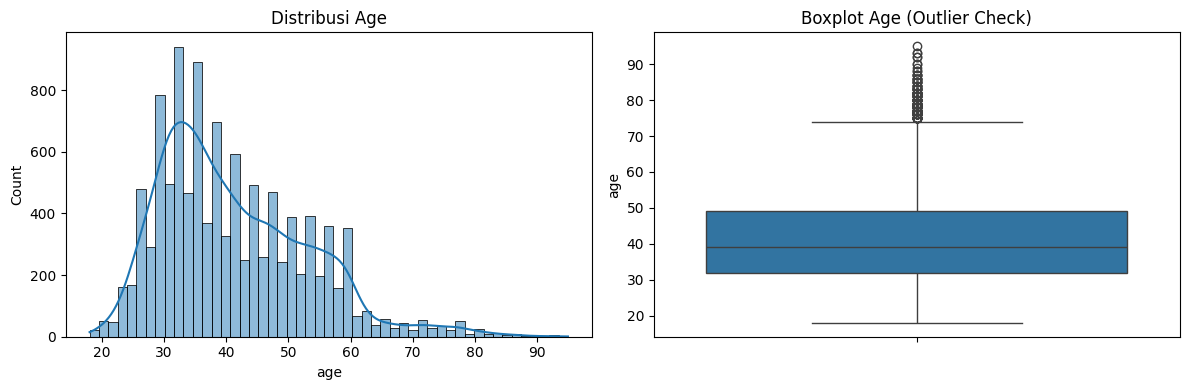

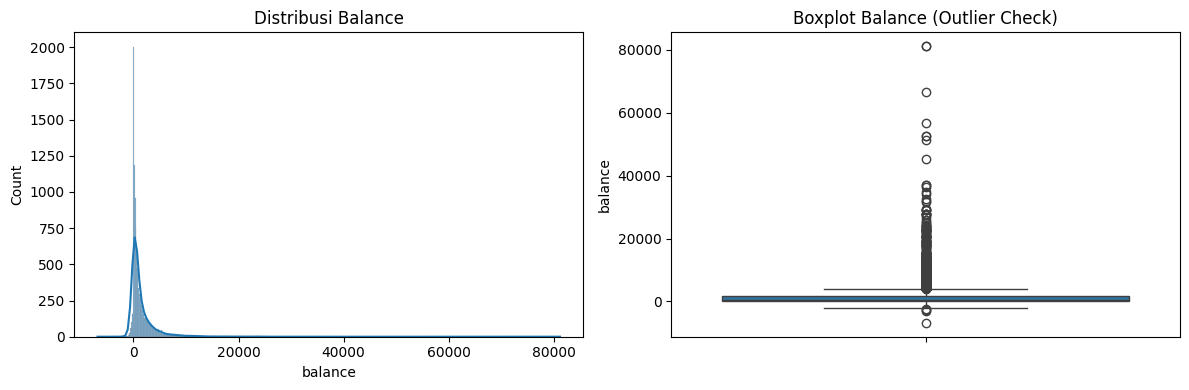

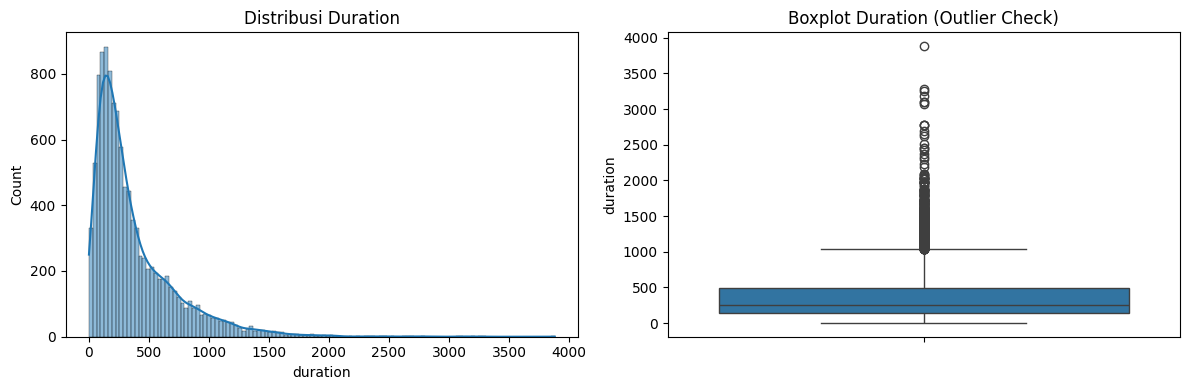

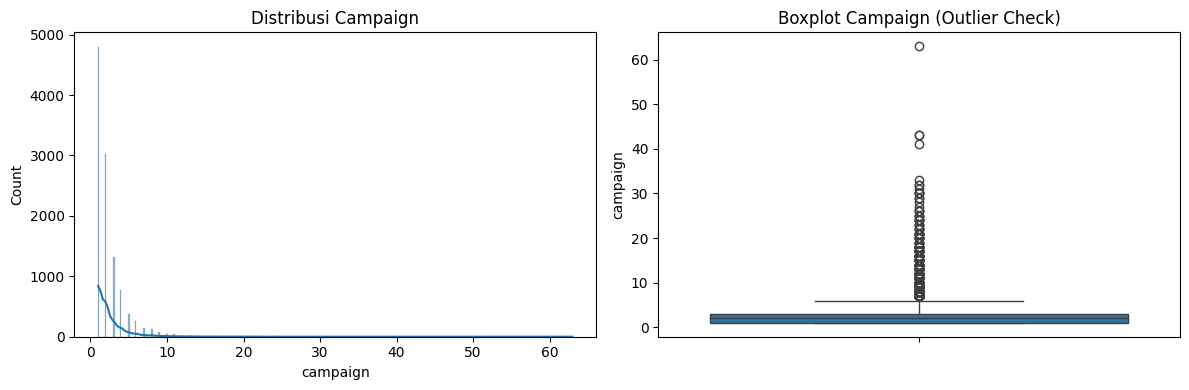

In [ ]:
numerical_features = ['age', 'balance', 'duration', 'campaign']

for feature in numerical_features:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df[feature], kde=True, ax=ax[0])
    ax[0].set_title(f'Distribusi {feature.capitalize()}')

    sns.boxplot(y=df[feature], ax=ax[1])
    ax[1].set_title(f'Boxplot {feature.capitalize()} (Outlier Check)')

    plt.tight_layout()
    plt.show()



---

# ***Fase 3: Data Preparation***


---






> Data Cleaning (Handling Missing Values & Special Values)

In [ ]:
X_initial = df.drop('deposit', axis=1)

median_pdays = X_initial[X_initial['pdays'] != -1]['pdays'].median()

for col in ['job', 'education', 'contact', 'poutcome']:
    if col in df.columns and df[col].dtype == 'object':
        mode_val = X_initial[col].mode()[0]
        df[col].replace('unknown', mode_val, inplace=True)

df['pdays'].replace(-1, median_pdays, inplace=True)

> Data Cleaning (Handling Outliers - balance)

In [ ]:
def handle_outliers_iqr_capping(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR

    data[column] = np.where(data[column] > upper_bound, upper_bound, data[column])
    return data

df = handle_outliers_iqr_capping(df.copy(), 'balance')

> Feature Engineering (Encoding dan Scaling)

In [ ]:
X = df.drop('deposit', axis=1)
y = df['deposit']
y_encoded = y.map({'yes': 1, 'no': 0})

categorical_cols = X.select_dtypes(include=['object']).columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

X_final = X_encoded.drop(columns=['day', 'previous'], errors='ignore')

numeric_cols_final = X_final.select_dtypes(include=['int64', 'float64']).columns.tolist()

scaler = StandardScaler()
X_final[numeric_cols_final] = scaler.fit_transform(X_final[numeric_cols_final])

global numeric_cols_final

> Analisis Korelasi


--- Analisis Korelasi dengan Target (Top 10) ---


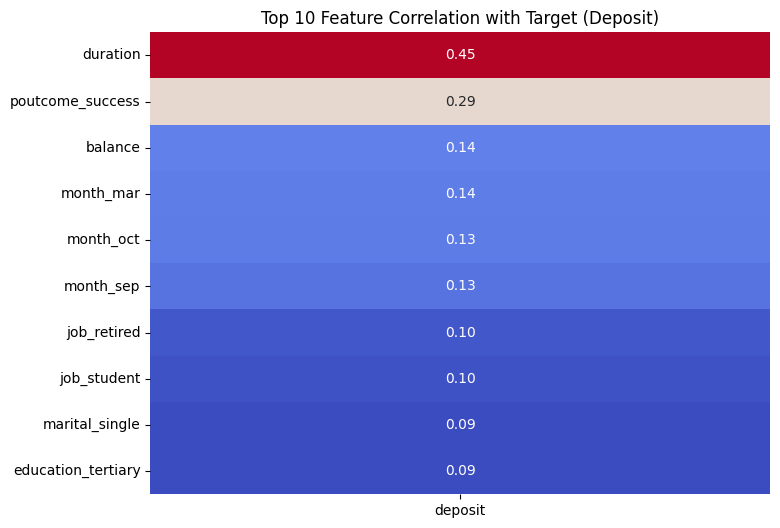

,Korelasi dengan Deposit
duration,0.451919
poutcome_success,0.286642
balance,0.137985
month_mar,0.135438
month_oct,0.133783
month_sep,0.126901
job_retired,0.103827
job_student,0.099953
marital_single,0.094632
education_tertiary,0.094598


In [ ]:
df_corr = pd.concat([X_final, y_encoded], axis=1)

correlation_matrix = df_corr.corr()
target_corr = correlation_matrix['deposit'].sort_values(ascending=False).head(11).drop('deposit')

print("\n--- Analisis Korelasi dengan Target (Top 10) ---")

plt.figure(figsize=(8, 6))
sns.heatmap(target_corr.to_frame(), annot=True, cmap='coolwarm', fmt=".2f", cbar=False)
plt.title('Top 10 Feature Correlation with Target (Deposit)')
plt.show()

display(target_corr.to_frame(name='Korelasi dengan Deposit'))

> Train - Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

pd.DataFrame({
    'Set': ['Training', 'Testing'],
    'Shape': [str(X_train.shape), str(X_test.shape)]
})

,Set,Shape
0,Training,"(8929, 37)"
1,Testing,"(2233, 37)"




---
# ***Fase 4: Modeling***
---



> Pilih dan Latih Algoritma ML (Logistic Regression - Baseline)

In [ ]:
log_model = LogisticRegression(random_state=42, solver='liblinear')
log_model.fit(X_train, y_train)

LogisticRegression(random_state=42, solver='liblinear')

> Pilih dan Latih Algoritma ML (Random Forest - Model Final)

In [ ]:
rf_model = RandomForestClassifier(random_state=42, n_estimators=200, n_jobs=-1, max_depth=10, min_samples_leaf=5)
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=5, n_estimators=200,
                       n_jobs=-1, random_state=42)



---
# ***Fase 5: Evaluation***

---



> Evaluasi Model dengan Metrik Relevan


--- Step 5.1: Hasil Metrik ---

--- Metrik Logistic Regression (Baseline) ---


,Metrik,Skor
0,Precision,0.8241
1,Recall,0.7836



Analisis Confusion Matrix:


,Predicted No,Predicted Yes
Actual No,998,177
Actual Yes,229,829



Interpretasi Komponen CM:
True Positives (TP): 829
False Positives (FP): 177 (Nasabah Non-Potensial yang SALAH diprediksi 'Yes')
False Negatives (FN): 229 (Nasabah Potensial yang TERLEWAT)


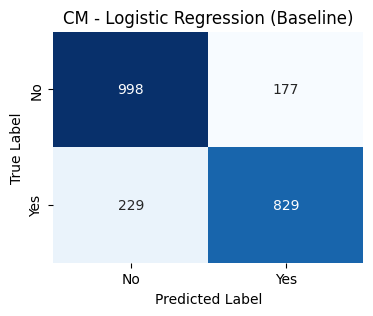


--- Metrik Random Forest (Final Model) ---


,Metrik,Skor
0,Precision,0.8009
1,Recall,0.8516



Analisis Confusion Matrix:


,Predicted No,Predicted Yes
Actual No,951,224
Actual Yes,157,901



Interpretasi Komponen CM:
True Positives (TP): 901
False Positives (FP): 224 (Nasabah Non-Potensial yang SALAH diprediksi 'Yes')
False Negatives (FN): 157 (Nasabah Potensial yang TERLEWAT)


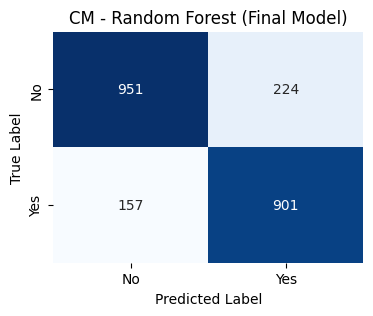

In [ ]:
def evaluate_model_full(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cm.ravel()

    print(f"\n--- Metrik {model_name} ---")

    metrics_data = {
        'Metrik': ['Precision', 'Recall'],
        'Skor': [f"{precision:.4f}", f"{recall:.4f}"]
    }
    display(pd.DataFrame(metrics_data))

    print("\nAnalisis Confusion Matrix:")
    cm_df = pd.DataFrame(cm, columns=['Predicted No', 'Predicted Yes'], index=['Actual No', 'Actual Yes'])
    display(cm_df)

    print(f"\nInterpretasi Komponen CM:")
    print(f"True Positives (TP): {TP}")
    print(f"False Positives (FP): {FP} (Nasabah Non-Potensial yang SALAH diprediksi 'Yes')")
    print(f"False Negatives (FN): {FN} (Nasabah Potensial yang TERLEWAT)")

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No', 'Yes'],
                yticklabels=['No', 'Yes'])
    plt.title(f'CM - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

print("\n--- Step 5.1: Hasil Metrik ---")
evaluate_model_full(log_model, X_test, y_test, "Logistic Regression (Baseline)")

evaluate_model_full(rf_model, X_test, y_test, "Random Forest (Final Model)")

> Interpretasi Hasil (Feature Importance)


--- Step 5.2: Feature Importance (Top 10) ---


,Importance Score
duration,0.511230
poutcome_success,0.088498
age,0.054208
housing_yes,0.048013
poutcome_unknown,0.045050
balance,0.042715
pdays,0.041947
month_may,0.026066
month_mar,0.021024
campaign,0.018730


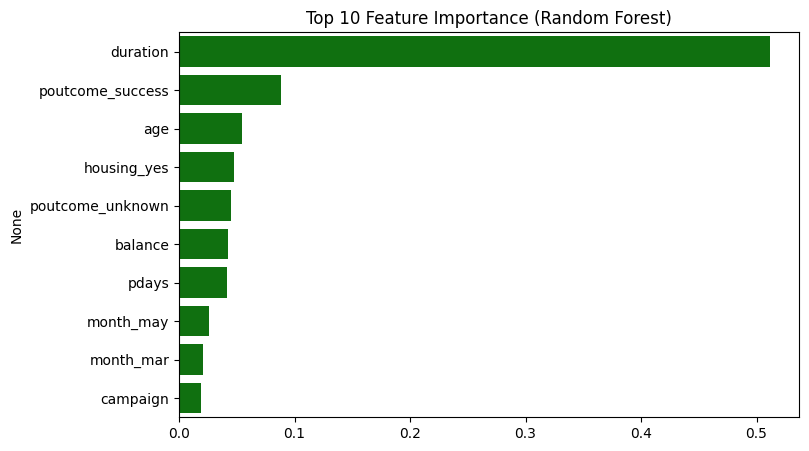

In [ ]:
feature_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top_features = feature_importances.nlargest(10)

print("\n--- Step 5.2: Feature Importance (Top 10) ---")
display(top_features.to_frame(name='Importance Score'))

plt.figure(figsize=(8, 5))
sns.barplot(x=top_features.values, y=top_features.index, color='green')
plt.title('Top 10 Feature Importance (Random Forest)')
plt.show()

> Uji ke Data Baru (Lead Scoring)

In [ ]:
median_pdays = 4.0

final_model = rf_model

print("\n--- Step 5.3: Uji Prediksi Data Baru ---")

new_customer_raw = pd.DataFrame({
    'age': [35, 50], 'job': ['management', 'blue-collar'],
    'marital': ['married', 'single'], 'education': ['tertiary', 'secondary'],
    'default': ['no', 'no'], 'balance': [8000.0, 100.0],
    'housing': ['no', 'yes'], 'loan': ['no', 'yes'],
    'contact': ['cellular', 'telephone'], 'day': [15, 2],
    'month': ['may', 'feb'], 'duration': [1200, 150],
    'campaign': [1, 5], 'pdays': [300, 50],
    'previous': [2, 1], 'poutcome': ['success', 'failure']
})

new_customer_processed = new_customer_raw.copy()
new_customer_processed['pdays'].replace(-1, median_pdays, inplace=True)

categorical_cols_for_new = new_customer_processed.select_dtypes(include=['object']).columns
new_customer_encoded = pd.get_dummies(new_customer_processed, columns=categorical_cols_for_new, drop_first=True)

columns_to_drop_final = ['previous', 'day']
new_customer_encoded = new_customer_encoded.drop(columns=columns_to_drop_final, errors='ignore')

missing_cols = set(X_train.columns) - set(new_customer_encoded.columns)
for col in missing_cols:
    new_customer_encoded[col] = 0
new_customer_encoded = new_customer_encoded[X_train.columns]

new_customer_encoded[numeric_cols_final] = scaler.transform(new_customer_encoded[numeric_cols_final])

predictions = final_model.predict(new_customer_encoded)
probabilities = final_model.predict_proba(new_customer_encoded)[:, 1]

new_customer_raw['Prediction_Label'] = predictions
new_customer_raw['Probability'] = probabilities
new_customer_raw['Prediction_Label'] = new_customer_raw['Prediction_Label'].map({1: 'Yes (Potensial)', 0: 'No (Non-Potensial)'})

print("\n--- Hasil Prediksi Lead Scoring ---")
new_customer_raw[['age', 'duration', 'balance', 'Prediction_Label', 'Probability']]


--- Step 5.3: Uji Prediksi Data Baru ---

--- Hasil Prediksi Lead Scoring ---


,age,duration,balance,Prediction_Label,Probability
0,35,1200,8000.0,Yes (Potensial),0.908169
1,50,150,100.0,No (Non-Potensial),0.322888
